# 02 — Experimental evaluation: top-down vs top-down + bottom-up

Questo notebook **non genera goal** e **non esegue il feedback loop**. Legge due insiemi di output già persistiti:

- `output/top_down/`: baseline top-down;
- `output/top_down_bottom_up/`: lo stesso stato iniziale dopo il ciclo bottom-up.

Per ciascun dataset confronta separatamente HLG e LLG contro la ground truth usando la stessa metrica semantica BERT/Hungarian già presente nel notebook di valutazione precedente. Calcola quindi **Precision, Recall e F1** per:

1. top-down only;
2. top-down + bottom-up;
3. delta bottom-up − top-down.

Il risultato permette di verificare direttamente se il feedback bottom-up migliora o peggiora la baseline, senza mescolare generazione ed evaluation nello stesso notebook.

In [1]:
from pathlib import Path
import json
import os
import socket
import sys

os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")

import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from scipy.optimize import linear_sum_assignment
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

NOTEBOOK_DIR = PROJECT_ROOT / "notebook"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

OUTPUT_ROOT = PROJECT_ROOT / "output"
TOP_DOWN_DIR = OUTPUT_ROOT / "top_down"
TOP_DOWN_BOTTOM_UP_DIR = OUTPUT_ROOT / "top_down_bottom_up"
BOTTOM_UP_ITERATIONS_DIR = OUTPUT_ROOT / "bottom_up_iterations"
EVALUATION_DIR = OUTPUT_ROOT / "evaluation" / "top_down_vs_bottom_up"
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)

from groundtruth import ALL_GROUNDTRUTHS, GROUNDTRUTH_BY_NAME

GROUNDTRUTHS = list(ALL_GROUNDTRUTHS)

print("Project root:", PROJECT_ROOT)
print("Top-down directory:", TOP_DOWN_DIR)
print("Top-down + bottom-up directory:", TOP_DOWN_BOTTOM_UP_DIR)
print("Evaluation output:", EVALUATION_DIR)

c:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement
Top-down directory: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\top_down
Top-down + bottom-up directory: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\top_down_bottom_up
Evaluation output: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up


## 1. Caricamento e pairing degli output

Il pairing viene fatto sul campo `name` del JSON, non sulla posizione dei file. Un dataset entra nel confronto solo se sono disponibili sia la baseline sia l'output con feedback e se esiste la relativa ground truth.

In [2]:
def load_json(path: Path):
    with path.open("r", encoding="utf-8") as f:
        return json.load(f)


def index_json_files(directory: Path, pattern: str):
    result = {}
    for path in sorted(directory.glob(pattern)):
        payload = load_json(path)
        dataset_name = payload.get("name")
        if not dataset_name:
            print(f"Skipping file without dataset name: {path}")
            continue
        if dataset_name in result:
            raise RuntimeError(
                f"More than one file found for dataset {dataset_name!r} in {directory}. "
                "Remove stale duplicates or narrow the file pattern."
            )
        result[dataset_name] = (path, payload)
    return result


baseline_by_dataset = index_json_files(TOP_DOWN_DIR, "*_top_down.json")
combined_by_dataset = index_json_files(TOP_DOWN_BOTTOM_UP_DIR, "*_top_down_bottom_up.json")
combined_by_dataset = {
    name: entry
    for name, entry in combined_by_dataset.items()
    if not entry[1].get("bottomUpError")
    and entry[1].get("finalHighLevelGoals") is not None
    and entry[1].get("finalLowLevelGoals") is not None
}

common_datasets = sorted(
    set(baseline_by_dataset)
    & set(combined_by_dataset)
    & set(GROUNDTRUTH_BY_NAME)
)

if not common_datasets:
    raise RuntimeError(
        "No complete baseline/feedback pair found. Run the two execution notebooks first."
    )

print(f"Comparable datasets: {len(common_datasets)}")
for dataset_name in common_datasets:
    print(
        f"- {dataset_name}\n"
        f"    baseline: {baseline_by_dataset[dataset_name][0].name}\n"
        f"    feedback: {combined_by_dataset[dataset_name][0].name}"
    )

missing_feedback = sorted(set(baseline_by_dataset) - set(combined_by_dataset))
if missing_feedback:
    print("\nBaselines without a bottom-up result:", missing_feedback)

Comparable datasets: 11
- Assegno Unico Universale - SIA Project 24 25
    baseline: Assegno Unico Universale - SIA Project 24 25_ZERO_SHOT_feedback_original_top_down_top_down.json
    feedback: Assegno Unico Universale - SIA Project 24 25_ZERO_SHOT_feedback_original_top_down_top_down_bottom_up.json
- Ethical Purchasing Group - SIA Project 22 23
    baseline: Ethical Purchasing Group - SIA Project 22 23_ZERO_SHOT_feedback_original_top_down_top_down.json
    feedback: Ethical Purchasing Group - SIA Project 22 23_ZERO_SHOT_feedback_original_top_down_top_down_bottom_up.json
- Event Organization Portal - SIA Project 21 22
    baseline: Event Organization Portal - SIA Project 21 22_ZERO_SHOT_feedback_original_top_down_top_down.json
    feedback: Event Organization Portal - SIA Project 21 22_ZERO_SHOT_feedback_original_top_down_top_down_bottom_up.json
- Fitness Tracker
    baseline: Fitness Tracker_ZERO_SHOT_feedback_original_top_down_top_down.json
    feedback: Fitness Tracker_ZERO_SHOT_fee

## 2. Estrazione delle collezioni di goal

La baseline usa le liste `highLevelGoals` e `lowLevelGoals`. L'output con feedback usa invece le collezioni finali restituite dall'orchestrator (`finalHighLevelGoals`, `finalLowLevelGoals`).

In [3]:
def goal_text(item) -> str:
    if item is None:
        return ""
    if isinstance(item, str):
        return item.strip()
    if isinstance(item, dict):
        name = item.get("name")
        if isinstance(name, str) and name.strip():
            return name.strip()
        description = item.get("description")
        if isinstance(description, str):
            return description.strip()
    return str(item).strip()


def extract_hlg(container):
    if container is None:
        return []
    items = container.get("goals", []) if isinstance(container, dict) else container
    return [text for item in items if (text := goal_text(item))]


def extract_llg(container):
    if container is None:
        return []
    items = container.get("low_level_goals", []) if isinstance(container, dict) else container
    return [text for item in items if (text := goal_text(item))]


def extract_cycle_status(payload):
    cycle = payload.get("globalGoalCycle") or {}
    return {
        "converged": bool(cycle.get("converged")),
        "stop_reason": cycle.get("stop_reason"),
        "completed_iterations": cycle.get("completed_iterations"),
    }


states = {}
for dataset_name in common_datasets:
    _, baseline = baseline_by_dataset[dataset_name]
    _, combined = combined_by_dataset[dataset_name]
    gt = GROUNDTRUTH_BY_NAME[dataset_name]

    states[dataset_name] = {
        "reference_hlg": [str(x).strip() for x in gt["highLevelGoals"] if str(x).strip()],
        "reference_llg": [str(x).strip() for x in gt["lowLevelGoals"] if str(x).strip()],
        "top_down_hlg": extract_hlg(baseline.get("structuredHighLevelGoals") or baseline.get("highLevelGoals")),
        "top_down_llg": extract_llg(baseline.get("structuredLowLevelGoals") or baseline.get("lowLevelGoals")),
        "feedback_hlg": extract_hlg(combined.get("finalHighLevelGoals")),
        "feedback_llg": extract_llg(combined.get("finalLowLevelGoals")),
        "cycle_status": extract_cycle_status(combined),
    }

for dataset_name, s in states.items():
    print(
        f"{dataset_name}: "
        f"GT HLG/LLG={len(s['reference_hlg'])}/{len(s['reference_llg'])} | "
        f"top-down={len(s['top_down_hlg'])}/{len(s['top_down_llg'])} | "
        f"+bottom-up={len(s['feedback_hlg'])}/{len(s['feedback_llg'])} | "
        f"converged={s['cycle_status']['converged']}"
    )

Assegno Unico Universale - SIA Project 24 25: GT HLG/LLG=4/28 | top-down=8/29 | +bottom-up=7/42 | converged=True
Ethical Purchasing Group - SIA Project 22 23: GT HLG/LLG=4/14 | top-down=9/46 | +bottom-up=8/43 | converged=True
Event Organization Portal - SIA Project 21 22: GT HLG/LLG=4/27 | top-down=14/69 | +bottom-up=12/62 | converged=True
Fitness Tracker: GT HLG/LLG=6/13 | top-down=4/23 | +bottom-up=4/21 | converged=True
Genome Nexus: GT HLG/LLG=3/30 | top-down=5/17 | +bottom-up=5/18 | converged=True
Gestao Hospital: GT HLG/LLG=4/18 | top-down=9/39 | +bottom-up=8/41 | converged=True
La Reine Marlene - SIA Project 23 24: GT HLG/LLG=10/32 | top-down=15/64 | +bottom-up=14/61 | converged=True
London Ambulance Service: GT HLG/LLG=2/3 | top-down=7/32 | +bottom-up=7/26 | converged=True
Planning Poker: GT HLG/LLG=5/33 | top-down=10/28 | +bottom-up=10/25 | converged=True
Recycling: GT HLG/LLG=5/25 | top-down=8/37 | +bottom-up=7/35 | converged=True
SIA Project 25 26: GT HLG/LLG=10/31 | top-down

## 3. Preparazione della metrica BERT/Hungarian

La metrica è la stessa logica usata nel precedente notebook sperimentale:

- preprocessing NLTK;
- embedding `bert-base-uncased` con mean pooling;
- cosine similarity tra goal generati e goal di riferimento;
- matching 1-a-1 ottimo tramite algoritmo ungherese;
- soft Precision = similarità totale / numero di goal generati;
- soft Recall = similarità totale / numero di goal di riferimento;
- F1 armonica di Precision e Recall.

In [4]:
NLTK_RESOURCES = {
    "punkt": ("tokenizers/punkt",),
    "punkt_tab": ("tokenizers/punkt_tab",),
    "wordnet": ("corpora/wordnet", "corpora/wordnet.zip"),
    "omw-1.4": ("corpora/omw-1.4", "corpora/omw-1.4.zip"),
    "stopwords": ("corpora/stopwords",),
}


def _resource_exists(candidates):
    for candidate in candidates:
        try:
            nltk.data.find(candidate)
            return True
        except LookupError:
            pass
    return False


previous_timeout = socket.getdefaulttimeout()
socket.setdefaulttimeout(45)
try:
    for package, candidates in NLTK_RESOURCES.items():
        if not _resource_exists(candidates):
            print(f"Downloading missing NLTK resource: {package}")
            ok = nltk.download(package, quiet=False, raise_on_error=False)
            if not ok:
                raise RuntimeError(f"Could not download NLTK resource: {package}")
finally:
    socket.setdefaulttimeout(previous_timeout)

BERT_MODEL_NAME = "bert-base-uncased"
BERT_BATCH_SIZE = 16
SIMILARITY_THRESHOLD = 0.65

print(f"Loading {BERT_MODEL_NAME}...")
tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)
model = AutoModel.from_pretrained(BERT_MODEL_NAME)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

print("Device:", device)

Loading bert-base-uncased...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2061.94it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cpu


In [5]:
class PaperAlignedGoalEvaluator:
    def __init__(self, tokenizer, model, device, batch_size=16, preprocess=False, similarity_threshold=0.65):
        self.tokenizer = tokenizer
        self.model = model
        self.device = device
        self.batch_size = batch_size
        self.preprocess = preprocess
        self.embedding_cache = {}
        self.similarity_threshold = similarity_threshold

    def preprocess_text(self, text):
        tokens = word_tokenize(text)
        filtered_tokens = [
            token for token in tokens
            if token not in stop_words and token.isalnum()
        ]
        stemmed_tokens = [stemmer.stem(token) for token in filtered_tokens]
        lemmatized_tokens = [lemmatizer.lemmatize(token) for token in stemmed_tokens]
        return " ".join(lemmatized_tokens)

    def _encode_missing(self, raw_texts):
        missing = [text for text in raw_texts if text not in self.embedding_cache]
        if not missing:
            return

        prepared = [
            self.preprocess_text(text) if self.preprocess else text
            for text in missing
        ]

        total_batches = (len(missing) + self.batch_size - 1) // self.batch_size
        for start in tqdm(
            range(0, len(missing), self.batch_size),
            total=total_batches,
            desc="BERT batches",
        ):
            raw_batch = missing[start:start + self.batch_size]
            text_batch = prepared[start:start + self.batch_size]

            encoded_input = self.tokenizer(
                text_batch,
                padding=True,
                truncation=True,
                return_tensors="pt",
            ).to(self.device)

            with torch.inference_mode():
                model_output = self.model(**encoded_input)

            token_embeddings = model_output.last_hidden_state
            attention_mask = encoded_input["attention_mask"]
            input_mask_expanded = (
                attention_mask.unsqueeze(-1)
                .expand(token_embeddings.size())
                .float()
            )

            sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, dim=1)
            sum_mask = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
            pooled = (sum_embeddings / sum_mask).detach().cpu()

            for text, embedding in zip(raw_batch, pooled):
                self.embedding_cache[text] = embedding

    def encode_texts(self, texts):
        self._encode_missing(texts)
        return torch.stack([self.embedding_cache[text] for text in texts])

    def compute_similarity(self, generated_goals, reference_goals):
        gen_embeddings = self.encode_texts(generated_goals)
        ref_embeddings = self.encode_texts(reference_goals)
        gen_norm = torch.nn.functional.normalize(gen_embeddings, p=2, dim=1)
        ref_norm = torch.nn.functional.normalize(ref_embeddings, p=2, dim=1)
        return torch.mm(gen_norm, ref_norm.transpose(0, 1)).numpy()

    def calculate_soft_f1(self, preds, refs):
        if not preds or not refs:
            return {"precision": 0.0, "recall": 0.0, "f1": 0.0, "matched_goal_count": 0}

        sim_matrix = self.compute_similarity(preds, refs)
        row_ind, col_ind = linear_sum_assignment(-sim_matrix)
        matched_similarities = sim_matrix[row_ind, col_ind]
        accepted = matched_similarities[matched_similarities >= self.similarity_threshold]
        total_similarity = float(accepted.sum())

        precision = total_similarity / len(preds)
        recall = total_similarity / len(refs)
        f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
        return {
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "matched_goal_count": int(len(accepted)),
        }


evaluator = PaperAlignedGoalEvaluator(
    tokenizer=tokenizer,
    model=model,
    device=device,
    batch_size=BERT_BATCH_SIZE,
    preprocess=False,
    similarity_threshold=SIMILARITY_THRESHOLD,
)

## 4. Precision, Recall e F1 separati per baseline e feedback

Ogni riga usa la stessa ground truth e cambia solo lo stato generato. Questo è il confronto principale da usare per rispondere alla domanda sperimentale: **il bottom-up migliora la qualità dei goal rispetto alla stessa pipeline top-down senza feedback?**

In [6]:
metric_rows = []

for dataset_name, s in states.items():
    status = s["cycle_status"]
    for level, reference, top_down, feedback in (
        (
            "High-Level Goals",
            s["reference_hlg"],
            s["top_down_hlg"],
            s["feedback_hlg"],
        ),
        (
            "Low-Level Goals",
            s["reference_llg"],
            s["top_down_llg"],
            s["feedback_llg"],
        ),
    ):
        for method, generated in (
            ("top_down", top_down),
            ("top_down_plus_bottom_up", feedback),
        ):
            m = evaluator.calculate_soft_f1(generated, reference)
            metric_rows.append(
                {
                    "dataset": dataset_name,
                    "level": level,
                    "method": method,
                    "generated_goal_count": len(generated),
                    "reference_goal_count": len(reference),
                    "precision": m["precision"],
                    "recall": m["recall"],
                    "f1": m["f1"],
                    "matched_goal_count": m["matched_goal_count"],
                    "unmatched_generated_count": len(generated) - m["matched_goal_count"],
                    "cycle_converged": status["converged"],
                    "cycle_stop_reason": status["stop_reason"],
                    "cycle_completed_iterations": status["completed_iterations"],
                }
            )

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))

BERT batches: 100%|██████████| 2/2 [00:00<00:00, 15.68it/s]


,dataset,level,method,generated_goal_count,reference_goal_count,precision,recall,f1,matched_goal_count,unmatched_generated_count,cycle_converged,cycle_stop_reason,cycle_completed_iterations
0,Assegno Unico Universale - SIA Project 24 25,High-Level Goals,top_down,8,4,0.3718,0.7437,0.4958,4,4,True,ALL_BRANCHES_CONFIRMED,5
1,Assegno Unico Universale - SIA Project 24 25,High-Level Goals,top_down_plus_bottom_up,7,4,0.4790,0.8383,0.6097,4,3,True,ALL_BRANCHES_CONFIRMED,5
2,Assegno Unico Universale - SIA Project 24 25,Low-Level Goals,top_down,29,28,0.2338,0.2422,0.2379,10,19,True,ALL_BRANCHES_CONFIRMED,5
3,Assegno Unico Universale - SIA Project 24 25,Low-Level Goals,top_down_plus_bottom_up,42,28,0.1158,0.1736,0.1389,7,35,True,ALL_BRANCHES_CONFIRMED,5
4,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,top_down,9,4,0.3771,0.8485,0.5222,4,5,True,ALL_BRANCHES_CONFIRMED,5
5,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,top_down_plus_bottom_up,8,4,0.4199,0.8398,0.5599,4,4,True,ALL_BRANCHES_CONFIRMED,5
6,Ethical Purchasing Group - SIA Project 22 23,Low-Level Goals,top_down,46,14,0.0287,0.0943,0.0440,2,44,True,ALL_BRANCHES_CONFIRMED,5
7,Ethical Purchasing Group - SIA Project 22 23,Low-Level Goals,top_down_plus_bottom_up,43,14,0.0307,0.0943,0.0463,2,41,True,ALL_BRANCHES_CONFIRMED,5
8,Event Organization Portal - SIA Project 21 22,High-Level Goals,top_down,14,4,0.1689,0.5912,0.2628,3,11,True,ALL_BRANCHES_CONFIRMED,8
9,Event Organization Portal - SIA Project 21 22,High-Level Goals,top_down_plus_bottom_up,12,4,0.2064,0.6192,0.3096,3,9,True,ALL_BRANCHES_CONFIRMED,8


## 5. Delta bottom-up − top-down

Un delta positivo indica miglioramento; un delta negativo indica peggioramento. Precision e Recall vanno interpretati insieme: ad esempio, aggiungere molti goal può aumentare Recall ma ridurre Precision.

In [7]:
baseline_df = (
    metrics_df[metrics_df["method"] == "top_down"]
    .set_index(["dataset", "level"])
)
feedback_df = (
    metrics_df[metrics_df["method"] == "top_down_plus_bottom_up"]
    .set_index(["dataset", "level"])
)

comparison_rows = []
for key in baseline_df.index.intersection(feedback_df.index):
    dataset_name, level = key
    base = baseline_df.loc[key]
    feedback = feedback_df.loc[key]
    comparison_rows.append(
        {
            "dataset": dataset_name,
            "level": level,
            "top_down_goal_count": int(base["generated_goal_count"]),
            "bottom_up_goal_count": int(feedback["generated_goal_count"]),
            "delta_goal_count": int(feedback["generated_goal_count"] - base["generated_goal_count"]),
            "top_down_precision": base["precision"],
            "bottom_up_precision": feedback["precision"],
            "delta_precision": feedback["precision"] - base["precision"],
            "top_down_recall": base["recall"],
            "bottom_up_recall": feedback["recall"],
            "delta_recall": feedback["recall"] - base["recall"],
            "top_down_f1": base["f1"],
            "bottom_up_f1": feedback["f1"],
            "delta_f1": feedback["f1"] - base["f1"],
            "cycle_converged": bool(feedback["cycle_converged"]),
            "cycle_stop_reason": feedback["cycle_stop_reason"],
        }
    )

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

print("\nRows where bottom-up improved F1:")
display(comparison_df[comparison_df["delta_f1"] > 0].sort_values("delta_f1", ascending=False).round(4))

print("\nRows where bottom-up worsened F1:")
display(comparison_df[comparison_df["delta_f1"] < 0].sort_values("delta_f1").round(4))

,dataset,level,top_down_goal_count,bottom_up_goal_count,delta_goal_count,top_down_precision,bottom_up_precision,delta_precision,top_down_recall,bottom_up_recall,delta_recall,top_down_f1,bottom_up_f1,delta_f1,cycle_converged,cycle_stop_reason
0,Assegno Unico Universale - SIA Project 24 25,High-Level Goals,8,7,-1,0.3718,0.4790,0.1072,0.7437,0.8383,0.0946,0.4958,0.6097,0.1139,True,ALL_BRANCHES_CONFIRMED
1,Assegno Unico Universale - SIA Project 24 25,Low-Level Goals,29,42,13,0.2338,0.1158,-0.1180,0.2422,0.1736,-0.0685,0.2379,0.1389,-0.0990,True,ALL_BRANCHES_CONFIRMED
2,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,9,8,-1,0.3771,0.4199,0.0428,0.8485,0.8398,-0.0087,0.5222,0.5599,0.0377,True,ALL_BRANCHES_CONFIRMED
3,Ethical Purchasing Group - SIA Project 22 23,Low-Level Goals,46,43,-3,0.0287,0.0307,0.0020,0.0943,0.0943,0.0000,0.0440,0.0463,0.0023,True,ALL_BRANCHES_CONFIRMED
4,Event Organization Portal - SIA Project 21 22,High-Level Goals,14,12,-2,0.1689,0.2064,0.0375,0.5912,0.6192,0.0279,0.2628,0.3096,0.0468,True,ALL_BRANCHES_CONFIRMED
5,Event Organization Portal - SIA Project 21 22,Low-Level Goals,69,62,-7,0.2812,0.3070,0.0259,0.7185,0.7050,-0.0135,0.4042,0.4278,0.0236,True,ALL_BRANCHES_CONFIRMED
6,Fitness Tracker,High-Level Goals,4,4,0,0.7769,0.7769,0.0000,0.5180,0.5180,0.0000,0.6216,0.6216,0.0000,True,ALL_BRANCHES_CONFIRMED
7,Fitness Tracker,Low-Level Goals,23,21,-2,0.4381,0.4796,0.0415,0.7750,0.7747,-0.0003,0.5597,0.5924,0.0327,True,ALL_BRANCHES_CONFIRMED
8,Genome Nexus,High-Level Goals,5,5,0,0.4271,0.4271,0.0000,0.7118,0.7118,0.0000,0.5339,0.5339,0.0000,True,ALL_BRANCHES_CONFIRMED
9,Genome Nexus,Low-Level Goals,17,18,1,0.1643,0.1519,-0.0124,0.0931,0.0911,-0.0020,0.1188,0.1139,-0.0049,True,ALL_BRANCHES_CONFIRMED



Rows where bottom-up improved F1:


,dataset,level,top_down_goal_count,bottom_up_goal_count,delta_goal_count,top_down_precision,bottom_up_precision,delta_precision,top_down_recall,bottom_up_recall,delta_recall,top_down_f1,bottom_up_f1,delta_f1,cycle_converged,cycle_stop_reason
0,Assegno Unico Universale - SIA Project 24 25,High-Level Goals,8,7,-1,0.3718,0.4790,0.1072,0.7437,0.8383,0.0946,0.4958,0.6097,0.1139,True,ALL_BRANCHES_CONFIRMED
18,Recycling,High-Level Goals,8,7,-1,0.4976,0.5789,0.0812,0.7962,0.8104,0.0142,0.6125,0.6754,0.0629,True,ALL_BRANCHES_CONFIRMED
4,Event Organization Portal - SIA Project 21 22,High-Level Goals,14,12,-2,0.1689,0.2064,0.0375,0.5912,0.6192,0.0279,0.2628,0.3096,0.0468,True,ALL_BRANCHES_CONFIRMED
2,Ethical Purchasing Group - SIA Project 22 23,High-Level Goals,9,8,-1,0.3771,0.4199,0.0428,0.8485,0.8398,-0.0087,0.5222,0.5599,0.0377,True,ALL_BRANCHES_CONFIRMED
7,Fitness Tracker,Low-Level Goals,23,21,-2,0.4381,0.4796,0.0415,0.7750,0.7747,-0.0003,0.5597,0.5924,0.0327,True,ALL_BRANCHES_CONFIRMED
12,La Reine Marlene - SIA Project 23 24,High-Level Goals,15,14,-1,0.5105,0.5470,0.0365,0.7658,0.7658,0.0000,0.6126,0.6381,0.0255,True,ALL_BRANCHES_CONFIRMED
5,Event Organization Portal - SIA Project 21 22,Low-Level Goals,69,62,-7,0.2812,0.3070,0.0259,0.7185,0.7050,-0.0135,0.4042,0.4278,0.0236,True,ALL_BRANCHES_CONFIRMED
13,La Reine Marlene - SIA Project 23 24,Low-Level Goals,64,61,-3,0.3920,0.4117,0.0197,0.7840,0.7848,0.0008,0.5227,0.5401,0.0174,True,ALL_BRANCHES_CONFIRMED
19,Recycling,Low-Level Goals,37,35,-2,0.5339,0.5539,0.0199,0.7902,0.7754,-0.0148,0.6373,0.6462,0.0089,True,ALL_BRANCHES_CONFIRMED
11,Gestao Hospital,Low-Level Goals,39,41,2,0.3342,0.3344,0.0003,0.7240,0.7618,0.0378,0.4573,0.4648,0.0075,True,ALL_BRANCHES_CONFIRMED



Rows where bottom-up worsened F1:


,dataset,level,top_down_goal_count,bottom_up_goal_count,delta_goal_count,top_down_precision,bottom_up_precision,delta_precision,top_down_recall,bottom_up_recall,delta_recall,top_down_f1,bottom_up_f1,delta_f1,cycle_converged,cycle_stop_reason
1,Assegno Unico Universale - SIA Project 24 25,Low-Level Goals,29,42,13,0.2338,0.1158,-0.1180,0.2422,0.1736,-0.0685,0.2379,0.1389,-0.0990,True,ALL_BRANCHES_CONFIRMED
10,Gestao Hospital,High-Level Goals,9,8,-1,0.3343,0.3060,-0.0283,0.7521,0.6119,-0.1402,0.4629,0.4079,-0.0549,True,ALL_BRANCHES_CONFIRMED
17,Planning Poker,Low-Level Goals,28,25,-3,0.7540,0.7602,0.0061,0.6398,0.5759,-0.0639,0.6922,0.6553,-0.0369,True,ALL_BRANCHES_CONFIRMED
20,SIA Project 25 26,High-Level Goals,15,14,-1,0.4783,0.4729,-0.0054,0.7174,0.6620,-0.0554,0.5739,0.5517,-0.0222,True,ALL_BRANCHES_CONFIRMED
21,SIA Project 25 26,Low-Level Goals,55,62,7,0.4302,0.3984,-0.0318,0.7633,0.7968,0.0335,0.5503,0.5312,-0.0191,True,ALL_BRANCHES_CONFIRMED
9,Genome Nexus,Low-Level Goals,17,18,1,0.1643,0.1519,-0.0124,0.0931,0.0911,-0.0020,0.1188,0.1139,-0.0049,True,ALL_BRANCHES_CONFIRMED


## 6. Riassunto macro tra dataset

La macro-media attribuisce lo stesso peso a ogni dataset. È utile come sintesi, mentre le righe per dataset restano necessarie per vedere dove il ciclo aiuta o danneggia la decomposizione.

In [8]:
macro_df = (
    metrics_df
    .groupby(["level", "method"], as_index=False)[["precision", "recall", "f1"]]
    .mean()
)

display(macro_df.round(4))

macro_pivot = macro_df.pivot(index="level", columns="method", values=["precision", "recall", "f1"])
print("\nMacro comparison:")
display(macro_pivot.round(4))

,level,method,precision,recall,f1
0,High-Level Goals,top_down,0.4112,0.7216,0.5019
1,High-Level Goals,top_down_plus_bottom_up,0.4359,0.7155,0.5210
2,Low-Level Goals,top_down,0.3264,0.5113,0.3840
3,Low-Level Goals,top_down_plus_bottom_up,0.3221,0.5030,0.3779



Macro comparison:


precision                           recall  \
method            top_down top_down_plus_bottom_up top_down   
level                                                         
High-Level Goals    0.4112                  0.4359   0.7216   
Low-Level Goals     0.3264                  0.3221   0.5113   

                                               f1                          
method           top_down_plus_bottom_up top_down top_down_plus_bottom_up  
level                                                                      
High-Level Goals                  0.7155   0.5019                  0.5210  
Low-Level Goals                   0.5030   0.3840                  0.3779

## 7. Andamento medio per iterazione

L'iterazione **0** rappresenta la baseline top-down. Per ogni iterazione successiva vengono letti gli stati completi salvati in `output/bottom_up_iterations/.../iteration_NNN.json` e vengono ricalcolate Precision, Recall e F1 contro la stessa ground truth.

La media dell'iterazione *N* include soltanto i dataset che hanno realmente eseguito l'iterazione *N*. Il numero `n` mostrato sull'asse indica quindi quanti dataset contribuiscono a quel punto: nelle iterazioni avanzate la media puÃ² riguardare meno dataset e va interpretata insieme a questo conteggio.

Dopo il grafico macro viene prodotto anche un grafico dettagliato a sei pannelli: prima HLG e poi LLG, con pannelli separati per Recall, Precision e F1. Ogni dataset Ã¨ rappresentato da una linea differente, che termina all'ultima iterazione realmente eseguita da quel dataset.

BERT batches: 100%|██████████| 1/1 [00:00<00:00, 38.45it/s]


,level,iteration,precision,recall,f1,dataset_count
0,High-Level Goals,0,0.4112,0.7216,0.5019,11
1,High-Level Goals,1,0.4163,0.7321,0.5087,11
2,High-Level Goals,2,0.4127,0.7231,0.5035,11
3,High-Level Goals,3,0.4202,0.7230,0.5097,11
4,High-Level Goals,4,0.3900,0.7508,0.5030,8
5,High-Level Goals,5,0.3963,0.7404,0.5051,8
6,High-Level Goals,6,0.4222,0.6939,0.5165,5
7,High-Level Goals,7,0.4222,0.6939,0.5165,5
8,High-Level Goals,8,0.3284,0.6310,0.4231,3
9,Low-Level Goals,0,0.3264,0.5113,0.3840,11


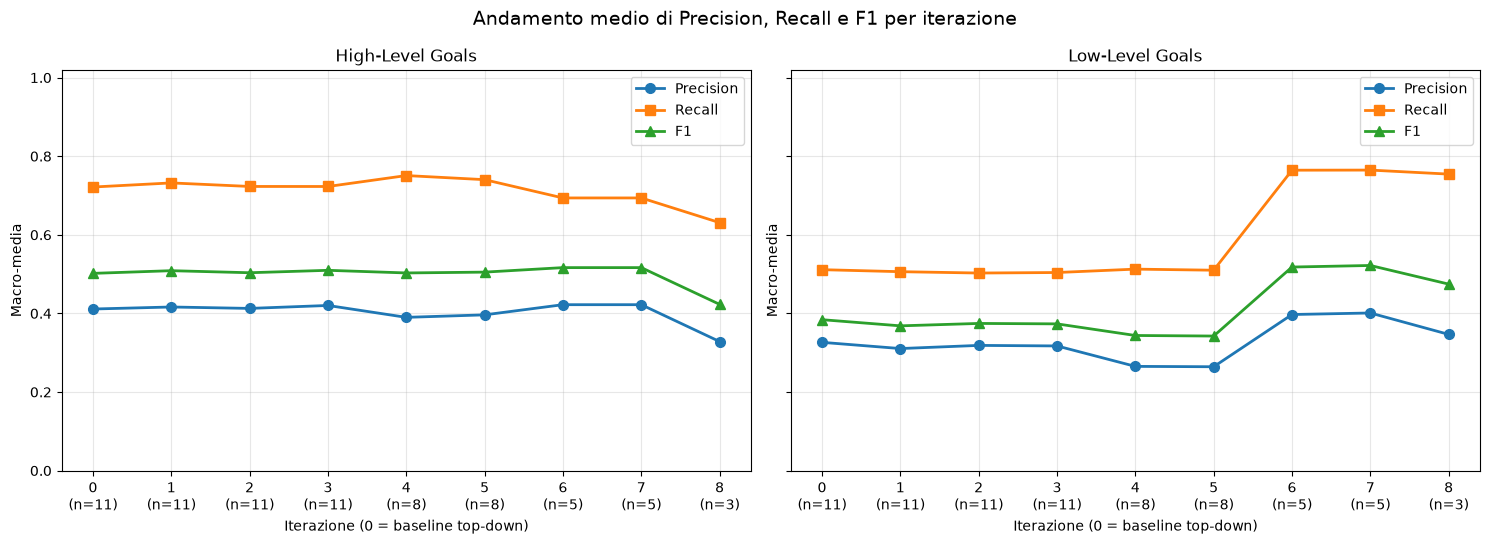

Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\iteration_metric_trend.png


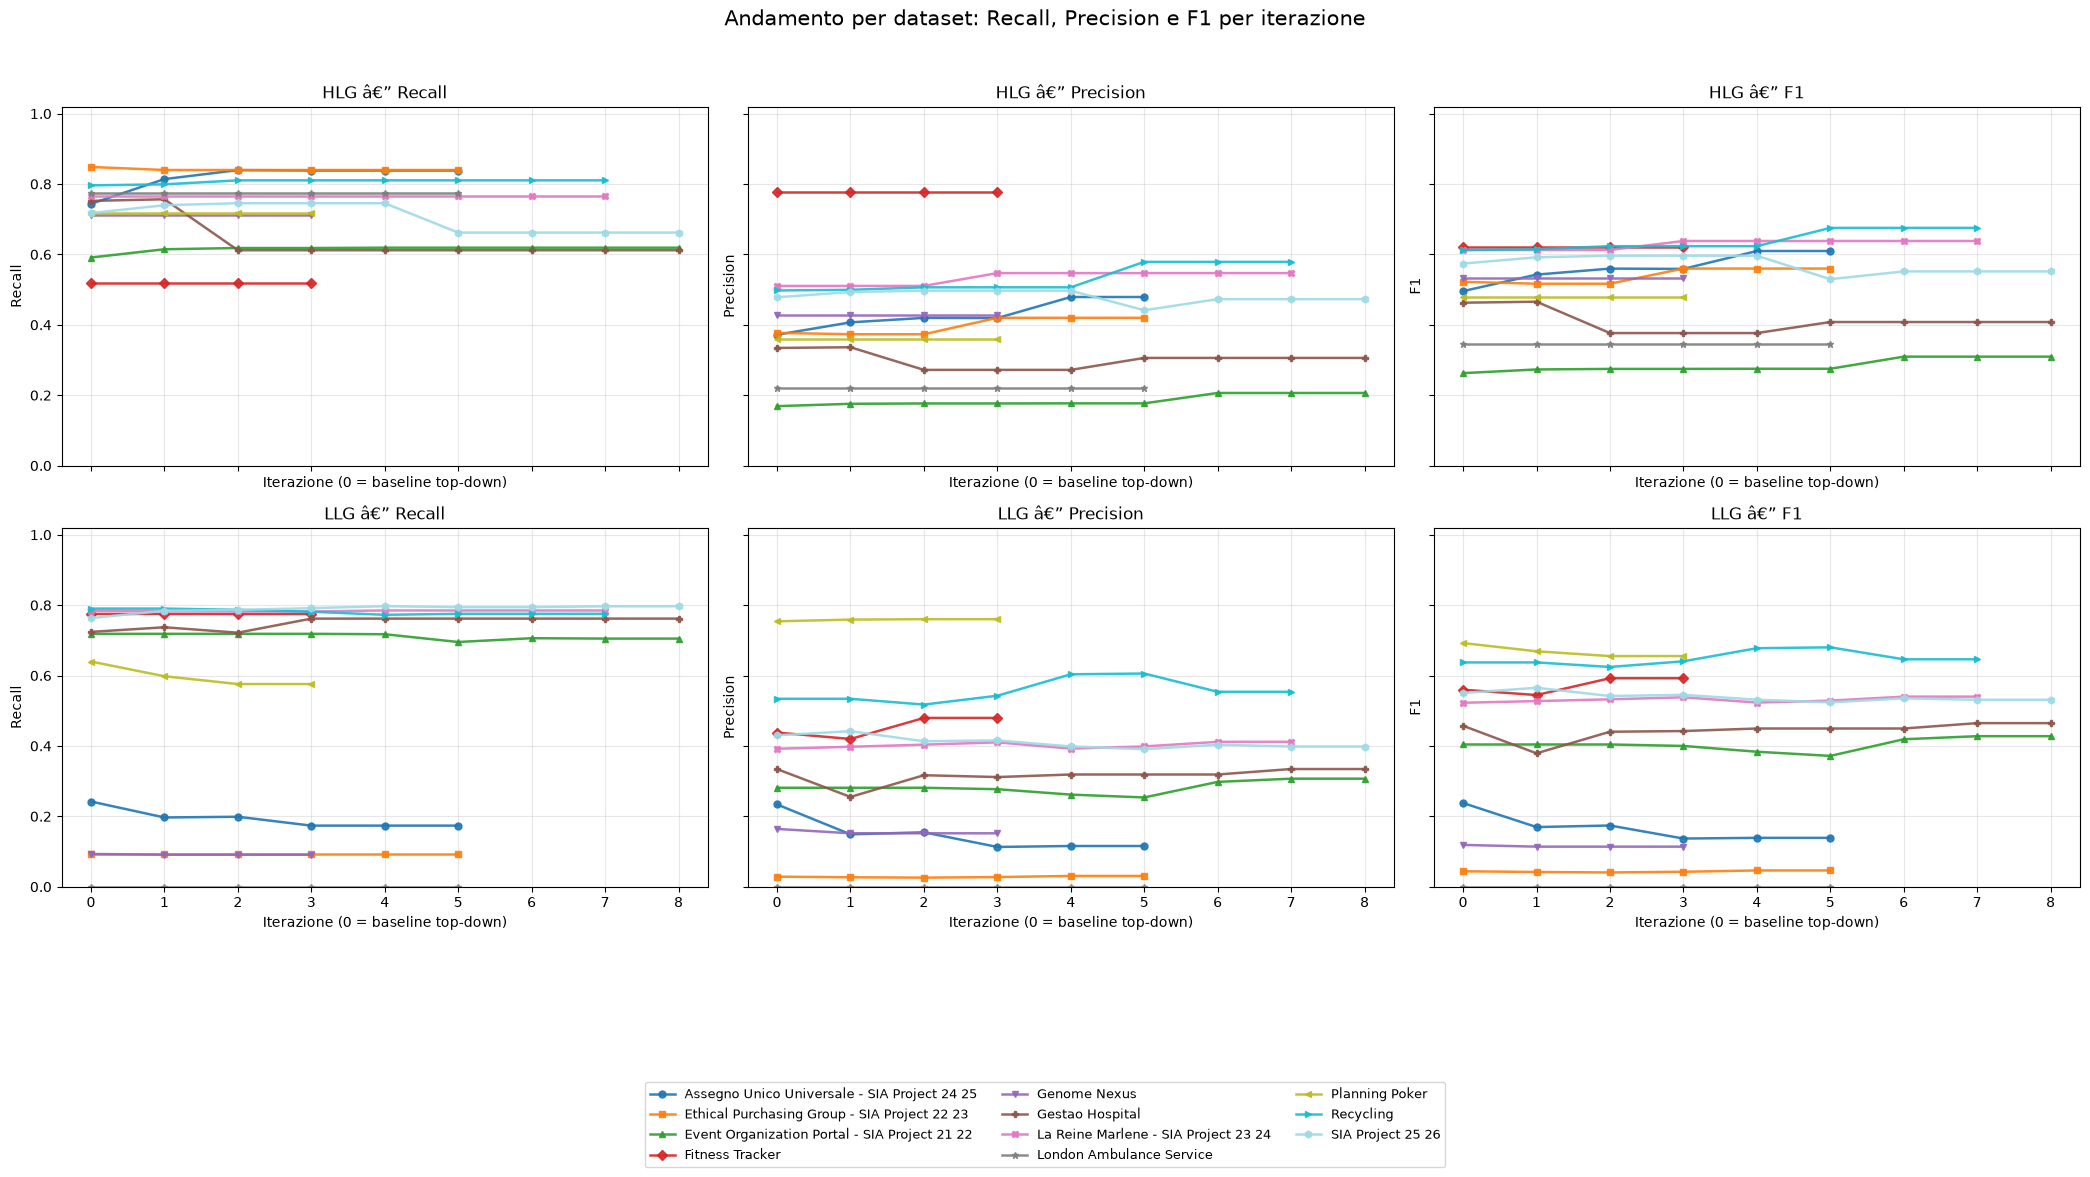

Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\iteration_metric_trend_by_dataset.png


In [9]:
def resolve_iteration_directory(combined_payload):
    configured = combined_payload.get("evaluationOutputDirectory")
    candidates = []
    if configured:
        configured_path = Path(configured)
        candidates.append(configured_path)
        candidates.append(BOTTOM_UP_ITERATIONS_DIR / configured_path.name)

    baseline_name = combined_payload.get("baselineSourceFile")
    if baseline_name:
        baseline_stem = Path(baseline_name).stem
        if baseline_stem.endswith("_top_down"):
            baseline_stem = baseline_stem[:-len("_top_down")]
        candidates.append(BOTTOM_UP_ITERATIONS_DIR / baseline_stem)

    for candidate in candidates:
        if candidate.is_dir():
            return candidate
    return None


iteration_metric_rows = []
missing_iteration_traces = []

for dataset_name, s in states.items():
    # Iteration 0 is the unmodified top-down baseline.
    for level, reference, generated in (
        ("High-Level Goals", s["reference_hlg"], s["top_down_hlg"]),
        ("Low-Level Goals", s["reference_llg"], s["top_down_llg"]),
    ):
        m = evaluator.calculate_soft_f1(generated, reference)
        iteration_metric_rows.append({
            "dataset": dataset_name,
            "level": level,
            "iteration": 0,
            "state": "top_down_baseline",
            "generated_goal_count": len(generated),
            "reference_goal_count": len(reference),
            **m,
        })

    _, combined = combined_by_dataset[dataset_name]
    iteration_directory = resolve_iteration_directory(combined)
    if iteration_directory is None:
        missing_iteration_traces.append(dataset_name)
        continue

    for trace_path in sorted(iteration_directory.glob("iteration_*.json")):
        trace = load_json(trace_path)
        iteration = int(trace.get("iteration") or trace_path.stem.rsplit("_", 1)[-1])
        for level, reference, generated in (
            ("High-Level Goals", s["reference_hlg"], extract_hlg(trace.get("high_level_goals"))),
            ("Low-Level Goals", s["reference_llg"], extract_llg(trace.get("low_level_goals"))),
        ):
            m = evaluator.calculate_soft_f1(generated, reference)
            iteration_metric_rows.append({
                "dataset": dataset_name,
                "level": level,
                "iteration": iteration,
                "state": "bottom_up_iteration",
                "generated_goal_count": len(generated),
                "reference_goal_count": len(reference),
                **m,
            })

iteration_metrics_df = pd.DataFrame(iteration_metric_rows).sort_values(
    ["level", "iteration", "dataset"]
).reset_index(drop=True)

iteration_macro_df = (
    iteration_metrics_df
    .groupby(["level", "iteration"], as_index=False)
    .agg(
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1=("f1", "mean"),
        dataset_count=("dataset", "nunique"),
    )
    .sort_values(["level", "iteration"])
)

display(iteration_macro_df.round(4))
if missing_iteration_traces:
    print("Dataset senza trace di iterazione:", missing_iteration_traces)

metric_styles = {
    "precision": {"label": "Precision", "marker": "o"},
    "recall": {"label": "Recall", "marker": "s"},
    "f1": {"label": "F1", "marker": "^"},
}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for axis, level in zip(axes, ("High-Level Goals", "Low-Level Goals")):
    level_df = iteration_macro_df[iteration_macro_df["level"] == level]
    for metric, style in metric_styles.items():
        axis.plot(
            level_df["iteration"],
            level_df[metric],
            linewidth=2,
            markersize=7,
            label=style["label"],
            marker=style["marker"],
        )
    axis.set_title(level)
    axis.set_xlabel("Iterazione (0 = baseline top-down)")
    axis.set_ylabel("Macro-media")
    axis.set_ylim(0, 1.02)
    axis.grid(True, alpha=0.3)
    axis.set_xticks(level_df["iteration"])
    axis.set_xticklabels([
        f"{int(row.iteration)}\n(n={int(row.dataset_count)})"
        for row in level_df.itertuples()
    ])
    axis.legend()

fig.suptitle("Andamento medio di Precision, Recall e F1 per iterazione", fontsize=14)
fig.tight_layout()
iteration_chart_path = EVALUATION_DIR / "iteration_metric_trend.png"
fig.savefig(iteration_chart_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", iteration_chart_path)

# Detailed view: one line per dataset, split by level and metric.
metric_columns = (
    ("recall", "Recall"),
    ("precision", "Precision"),
    ("f1", "F1"),
)
level_rows = (
    ("High-Level Goals", "HLG"),
    ("Low-Level Goals", "LLG"),
)
dataset_names = sorted(iteration_metrics_df["dataset"].unique())
color_map = plt.get_cmap("tab20", max(len(dataset_names), 1))
markers = ("o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "8")
dataset_styles = {
    dataset: {
        "color": color_map(index),
        "marker": markers[index % len(markers)],
    }
    for index, dataset in enumerate(dataset_names)
}
all_iterations = sorted(iteration_metrics_df["iteration"].unique())

detail_fig, detail_axes = plt.subplots(
    2, 3, figsize=(21, 12), sharex=True, sharey=True
)
for row_index, (level, level_label) in enumerate(level_rows):
    level_df = iteration_metrics_df[iteration_metrics_df["level"] == level]
    for column_index, (metric, metric_label) in enumerate(metric_columns):
        axis = detail_axes[row_index, column_index]
        for dataset in dataset_names:
            dataset_df = (
                level_df[level_df["dataset"] == dataset]
                .sort_values("iteration")
            )
            if dataset_df.empty:
                continue
            style = dataset_styles[dataset]
            axis.plot(
                dataset_df["iteration"],
                dataset_df[metric],
                label=dataset,
                color=style["color"],
                marker=style["marker"],
                linewidth=1.8,
                markersize=5,
                alpha=0.9,
            )
        axis.set_title(f"{level_label} â€” {metric_label}")
        axis.set_xlabel("Iterazione (0 = baseline top-down)")
        axis.set_ylabel(metric_label)
        axis.set_ylim(0, 1.02)
        axis.set_xticks(all_iterations)
        axis.grid(True, alpha=0.3)

legend_handles, legend_labels = detail_axes[0, 0].get_legend_handles_labels()
detail_fig.legend(
    legend_handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=3,
    fontsize=9,
)
detail_fig.suptitle(
    "Andamento per dataset: Recall, Precision e F1 per iterazione",
    fontsize=15,
)
detail_fig.tight_layout(rect=(0, 0.20, 1, 0.96))
iteration_dataset_chart_path = (
    EVALUATION_DIR / "iteration_metric_trend_by_dataset.png"
)
detail_fig.savefig(
    iteration_dataset_chart_path, dpi=200, bbox_inches="tight"
)
plt.show()
print("Saved:", iteration_dataset_chart_path)

## 8. Export

I CSV seguenti sono già separati tra metriche assolute e delta A/B, così possono essere usati direttamente nelle tabelle della tesi.

In [10]:
metrics_path = EVALUATION_DIR / "top_down_vs_bottom_up_metrics.csv"
comparison_path = EVALUATION_DIR / "top_down_vs_bottom_up_deltas.csv"
macro_path = EVALUATION_DIR / "top_down_vs_bottom_up_macro_summary.csv"
iteration_metrics_path = EVALUATION_DIR / "iteration_metrics.csv"
iteration_macro_path = EVALUATION_DIR / "iteration_macro_summary.csv"
summary_path = EVALUATION_DIR / "evaluation_summary.json"

metrics_df.to_csv(metrics_path, index=False)
comparison_df.to_csv(comparison_path, index=False)
macro_df.to_csv(macro_path, index=False)
iteration_metrics_df.to_csv(iteration_metrics_path, index=False)
iteration_macro_df.to_csv(iteration_macro_path, index=False)

summary = {
    "datasets": common_datasets,
    "metric": {
        "embedding_model": BERT_MODEL_NAME,
        "matching": f"Hungarian one-to-one matching with cosine similarity >= {SIMILARITY_THRESHOLD}",
        "preprocessing": "Raw goal text; no stemming or lemmatization before BERT",
        "iteration_aggregation": "Macro mean over datasets that actually reached each iteration; iteration 0 is the top-down baseline",
    },
    "outputs": {
        "metrics_csv": str(metrics_path),
        "deltas_csv": str(comparison_path),
        "macro_summary_csv": str(macro_path),
        "iteration_metrics_csv": str(iteration_metrics_path),
        "iteration_macro_summary_csv": str(iteration_macro_path),
        "iteration_trend_chart": str(iteration_chart_path),
        "iteration_dataset_trend_chart": str(iteration_dataset_chart_path),
    },
}
with summary_path.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

for path in (
    metrics_path, comparison_path, macro_path, iteration_metrics_path,
    iteration_macro_path, iteration_chart_path,
    iteration_dataset_chart_path, summary_path,
):
    print("Saved:", path)

Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\top_down_vs_bottom_up_metrics.csv
Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\top_down_vs_bottom_up_deltas.csv
Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\top_down_vs_bottom_up_macro_summary.csv
Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\iteration_metrics.csv
Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\iteration_macro_summary.csv
Saved: C:\Users\agnes\Desktop\tesi originale\LLM_MultiAgentChain_GoalOrientedAPIAlignement\output\evaluation\top_down_vs_bottom_up\iteration_metric_trend.png
Saved: C:\Users\agnes\Desktop\